<a href="https://colab.research.google.com/github/Samar97adel/Machine-learning/blob/main/Dry_Bean_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
!gdown('https://docs.google.com/spreadsheets/d/12zIYYjnXKDYAYVuzh5OusyKrs7865OWn/edit?usp=drive_link&ouid=107080881562734679210&rtpof=true&sd=true')

/bin/bash: -c: line 1: syntax error near unexpected token `'https://docs.google.com/spreadsheets/d/12zIYYjnXKDYAYVuzh5OusyKrs7865OWn/edit?usp=drive_link&ouid=107080881562734679210&rtpof=true&sd=true''
/bin/bash: -c: line 1: `gdown('https://docs.google.com/spreadsheets/d/12zIYYjnXKDYAYVuzh5OusyKrs7865OWn/edit?usp=drive_link&ouid=107080881562734679210&rtpof=true&sd=true')'


In [50]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110


In [5]:
df = pd.read_excel("/content/Dry_Bean_Dataset.xlsx", sheet_name="Dry_Beans_Dataset")
df = df.rename(columns={"AspectRation": "AspectRatio", "roundness": "Roundness"})  # تصحيح أسماء
print("Shape:", df.shape)
df.head()

Shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [6]:
df.info()
print("\nMissing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
df.describe().T.round(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRatio      13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  Roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.285,29324.096,20420.000,36328.000,44652.000,61332.000,254616.000
Perimeter,13611.0,855.283,214.290,524.736,703.523,794.941,977.213,1985.370
MajorAxisLength,13611.0,320.142,85.694,183.601,253.304,296.883,376.495,738.860
MinorAxisLength,13611.0,202.271,44.970,122.513,175.848,192.432,217.032,460.198
AspectRatio,13611.0,1.583,0.247,1.025,1.432,1.551,1.707,2.430
Eccentricity,13611.0,0.751,0.092,0.219,0.716,0.764,0.810,0.911
ConvexArea,13611.0,53768.200,29774.916,20684.000,36714.500,45178.000,62294.000,263261.000
EquivDiameter,13611.0,253.064,59.177,161.244,215.068,238.438,279.446,569.374
Extent,13611.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13611.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


In [8]:
FEATURES = [c for c in df.columns if c != "Class"]
CLASSES = df["Class"].value_counts().index.tolist()
print(len(FEATURES), "features |", len(CLASSES), "classes")

16 features | 7 classes


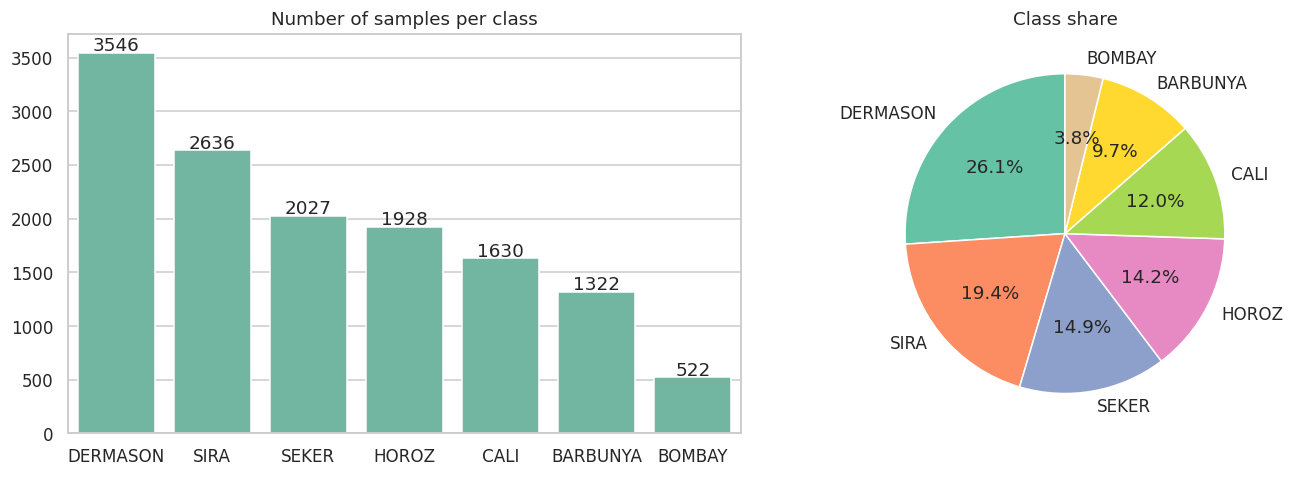

Imbalance ratio (max/min): 6.79


In [9]:
counts = df["Class"].value_counts()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=counts.index, y=counts.values, ax=ax[0])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 20, v, ha="center")
ax[0].set_title("Number of samples per class"); ax[0].set_xlabel("")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90)
ax[1].set_title("Class share")
plt.tight_layout(); plt.show()
print("Imbalance ratio (max/min):", round(counts.max()/counts.min(), 2))

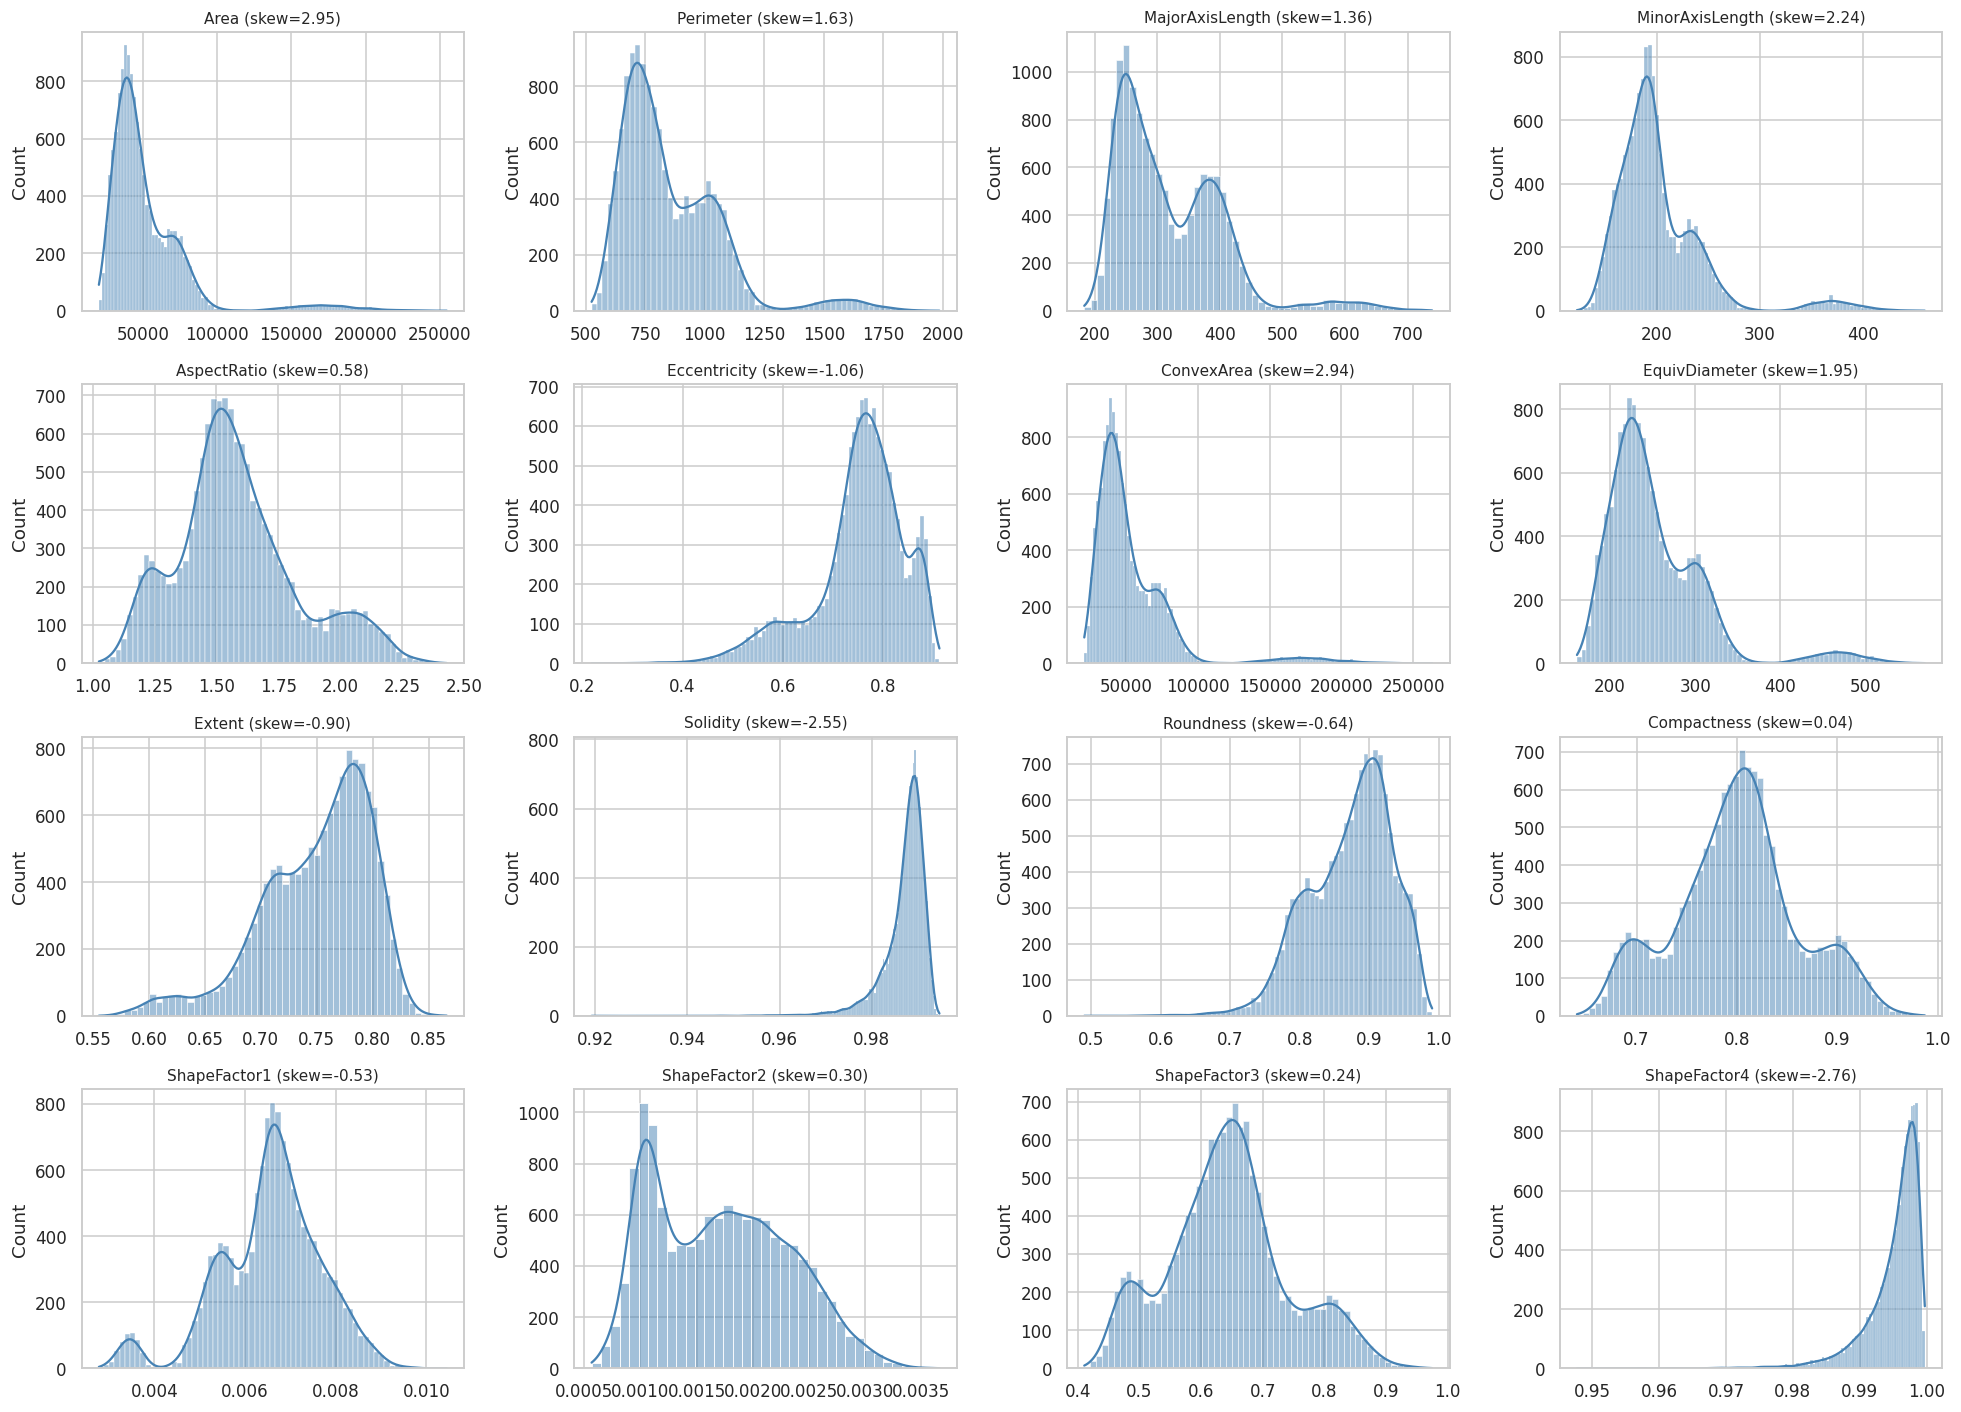

,skewness
Area,2.95
ConvexArea,2.94
MinorAxisLength,2.24
EquivDiameter,1.95
Perimeter,1.63
MajorAxisLength,1.36
AspectRatio,0.58
ShapeFactor2,0.30
ShapeFactor3,0.24
Compactness,0.04


In [10]:
fig, axes = plt.subplots(4, 4, figsize=(18, 13))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{col} (skew={df[col].skew():.2f})", fontsize=10)
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

df[FEATURES].skew().sort_values(ascending=False).round(2).to_frame("skewness")

,outliers,pct
Eccentricity,843,6.19
Solidity,778,5.72
ShapeFactor4,767,5.64
MinorAxisLength,569,4.18
Area,551,4.05
ConvexArea,550,4.04
ShapeFactor1,533,3.92
EquivDiameter,526,3.86
Perimeter,500,3.67
AspectRatio,473,3.48


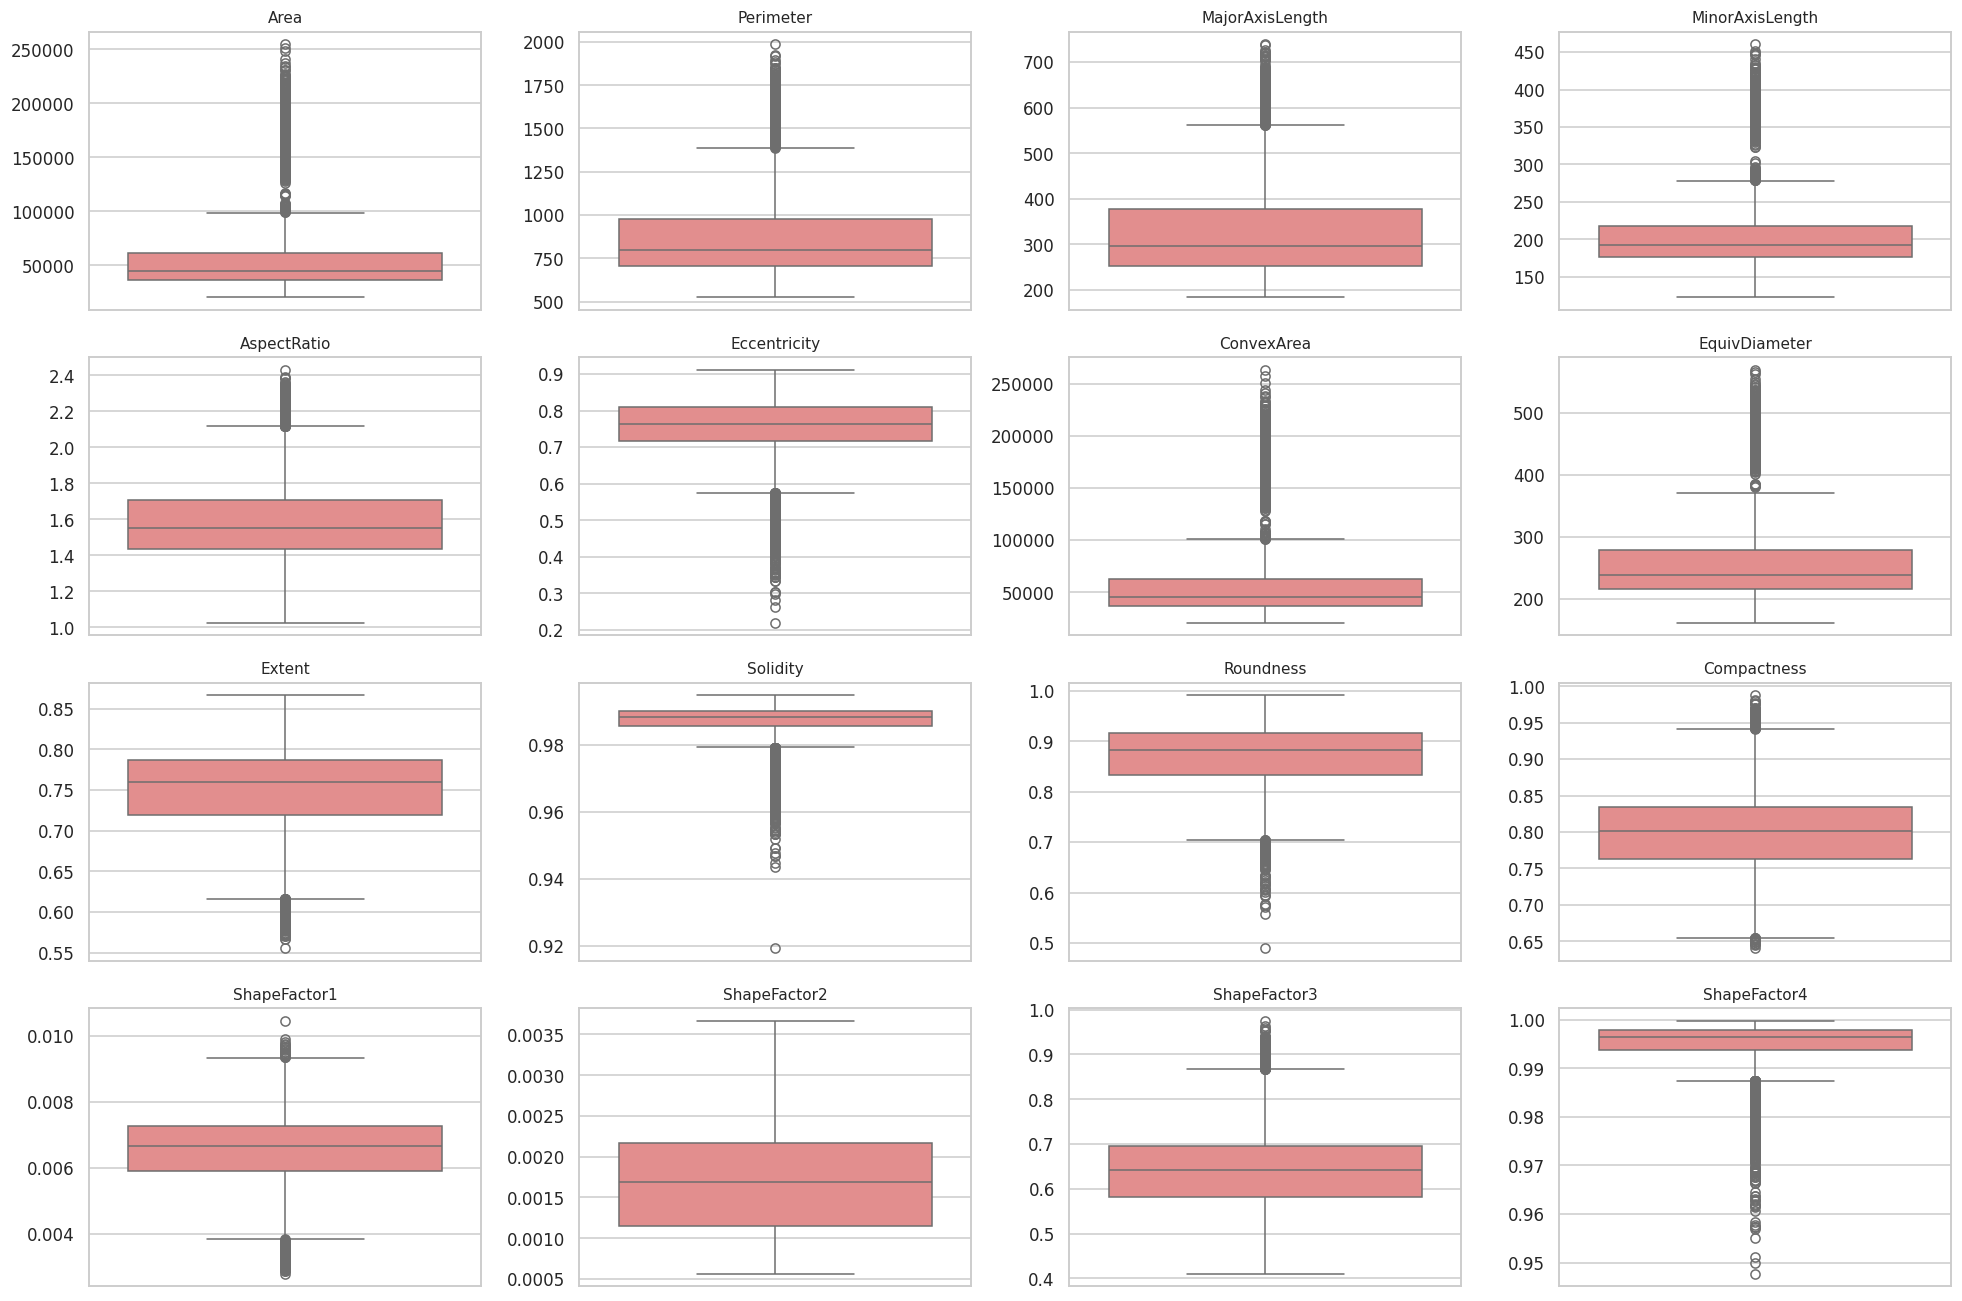

In [12]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum()

out = pd.DataFrame({"outliers": [iqr_outliers(df[c]) for c in FEATURES]}, index=FEATURES)
out["pct"] = (out["outliers"] / len(df) * 100).round(2)
display(out.sort_values("outliers", ascending=False))

fig, axes = plt.subplots(4, 4, figsize=(18, 12))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(y=df[col], ax=ax, color="lightcoral"); ax.set_title(col, fontsize=10); ax.set_ylabel("")
plt.tight_layout(); plt.show()

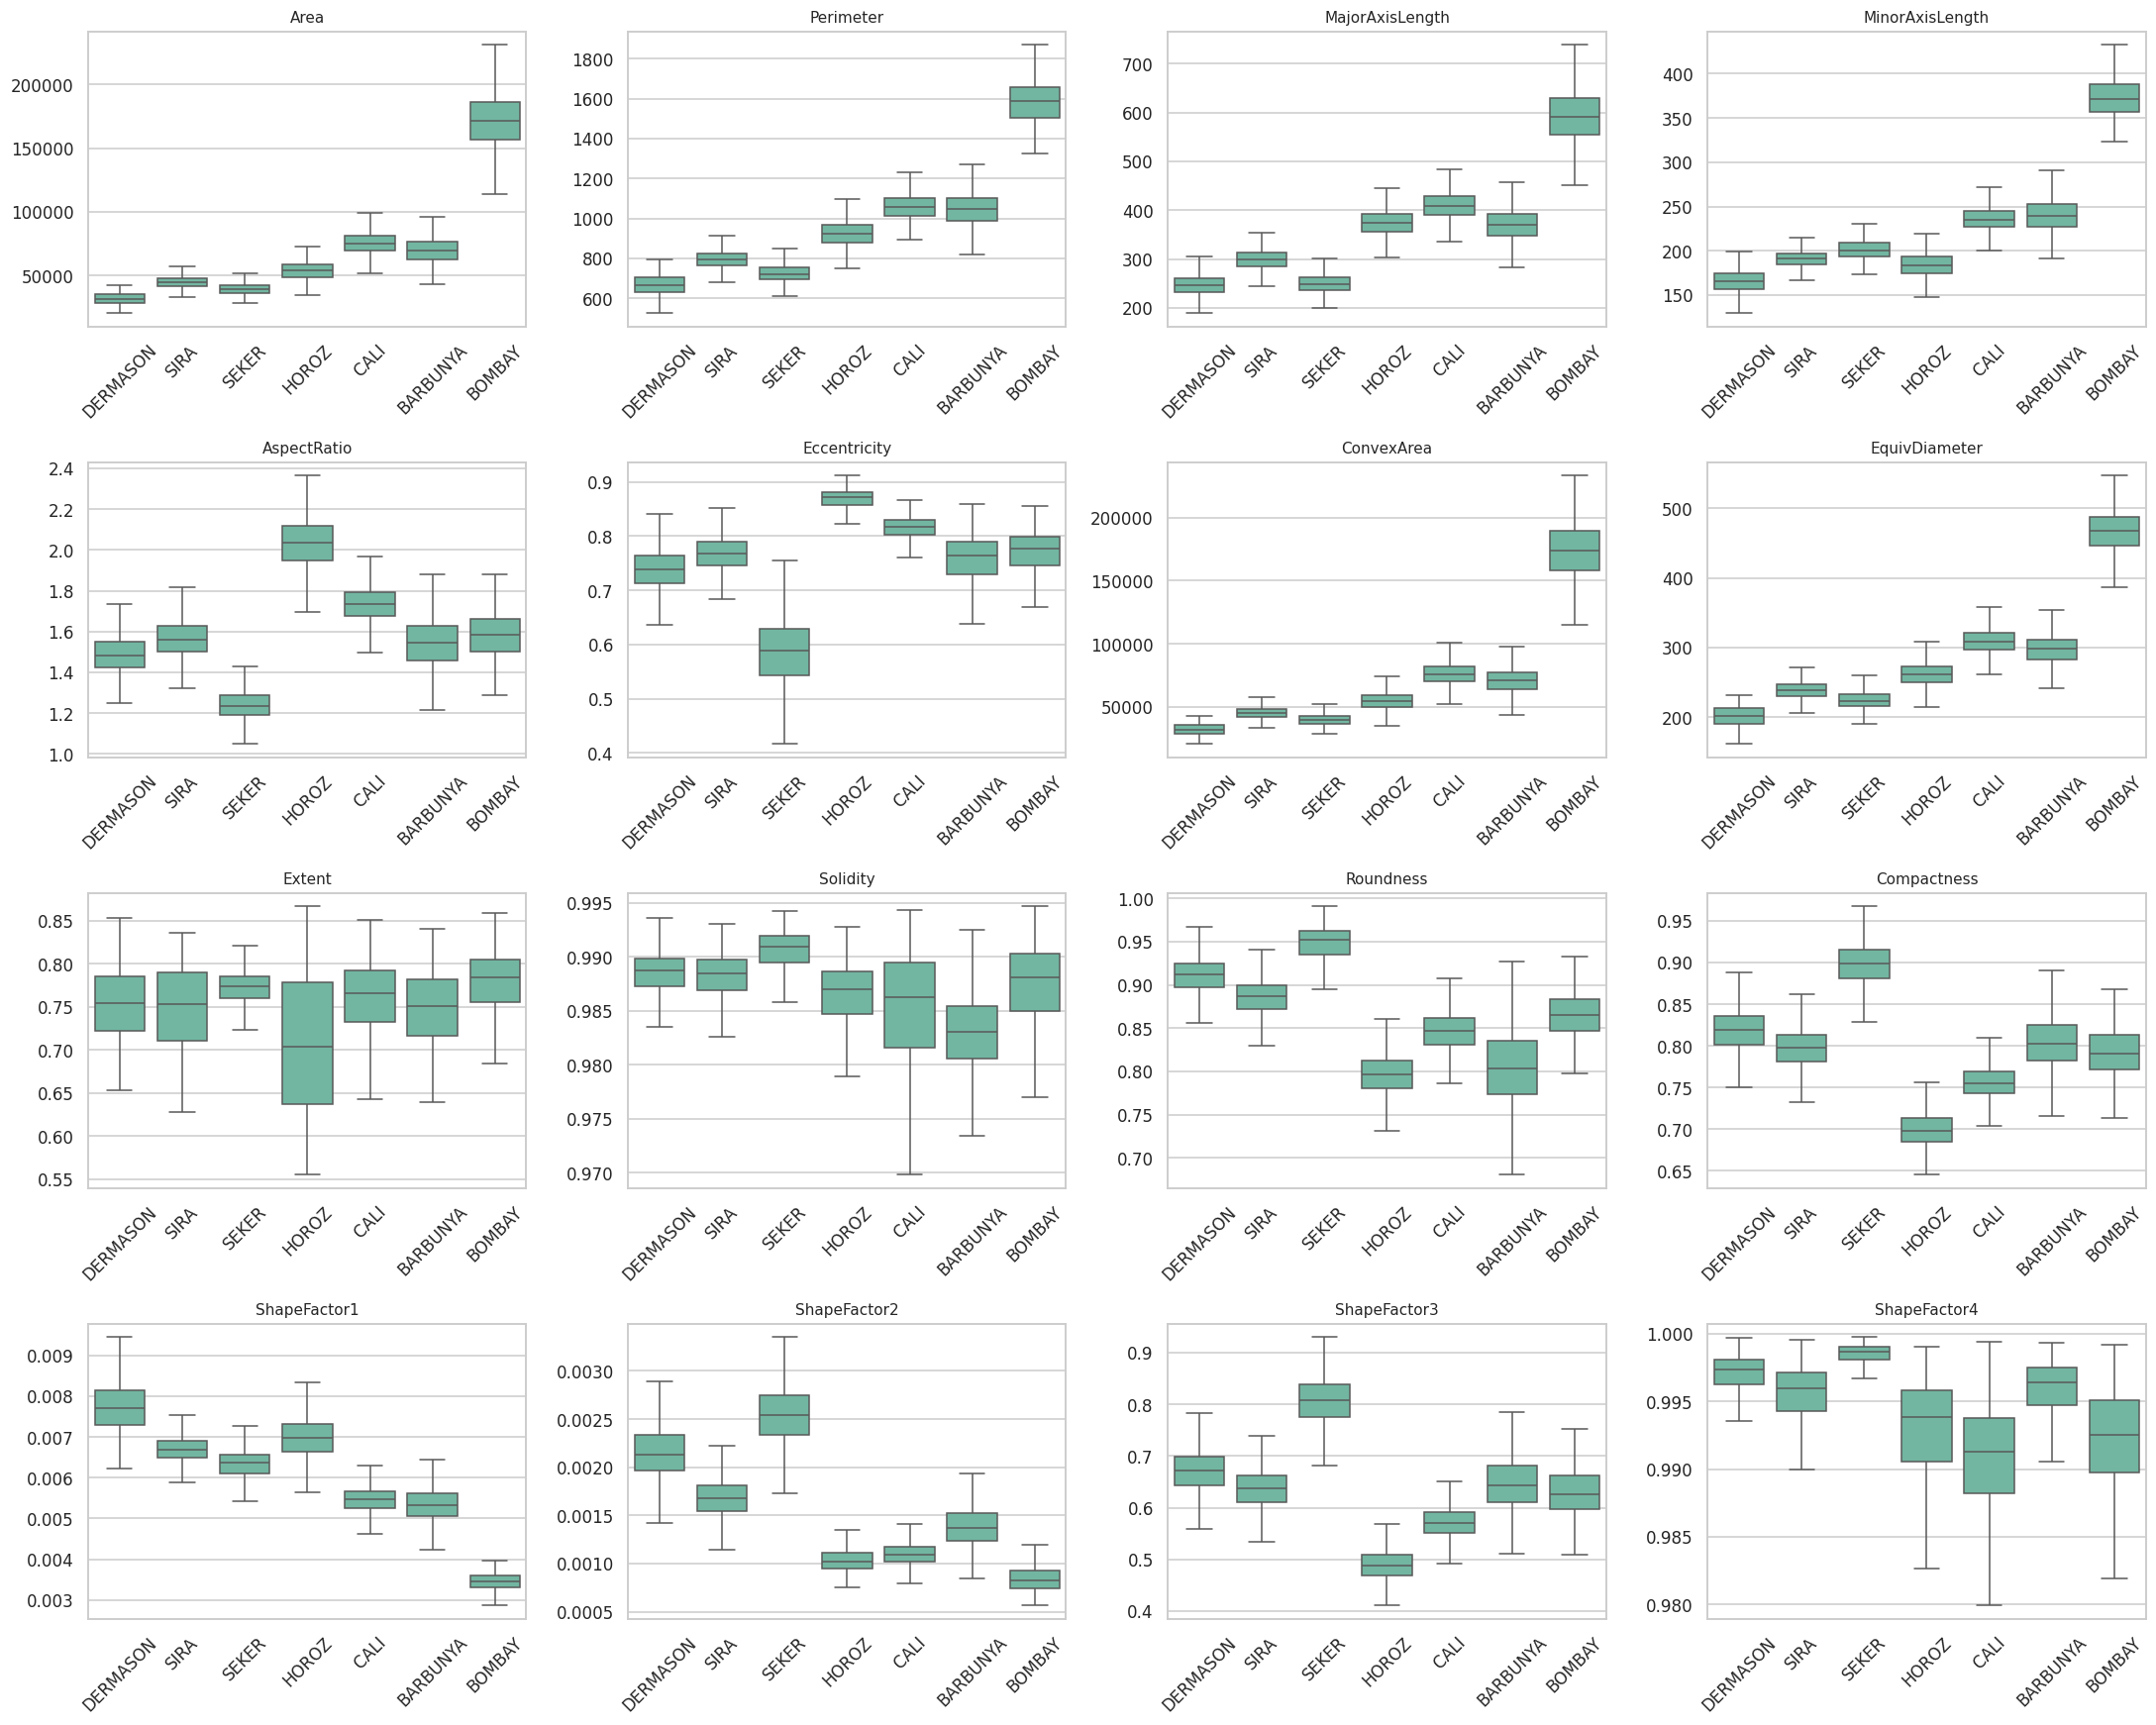

In [13]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df, x="Class", y=col, order=CLASSES, ax=ax, showfliers=False)
    ax.set_title(col, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

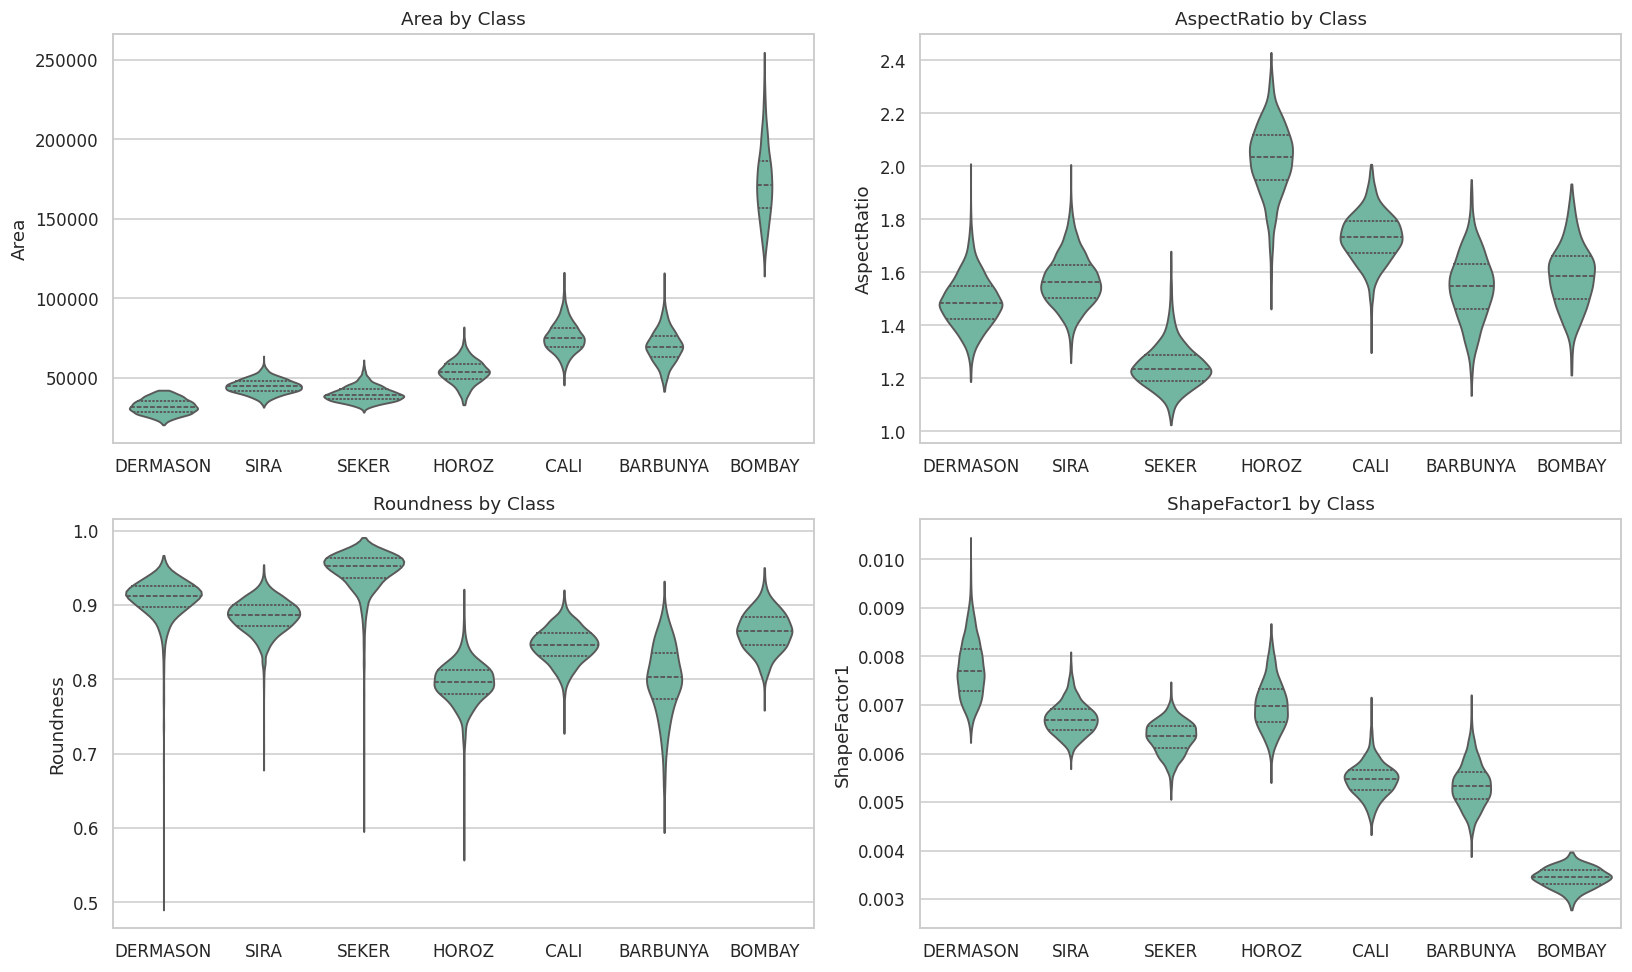

In [14]:
# Violin plots لأهم الـ features اللي بتفرّق بين الأصناف
key = ["Area", "AspectRatio", "Roundness", "ShapeFactor1"]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.ravel(), key):
    sns.violinplot(data=df, x="Class", y=col, order=CLASSES, ax=ax, inner="quartile", cut=0)
    ax.set_title(f"{col} by Class"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

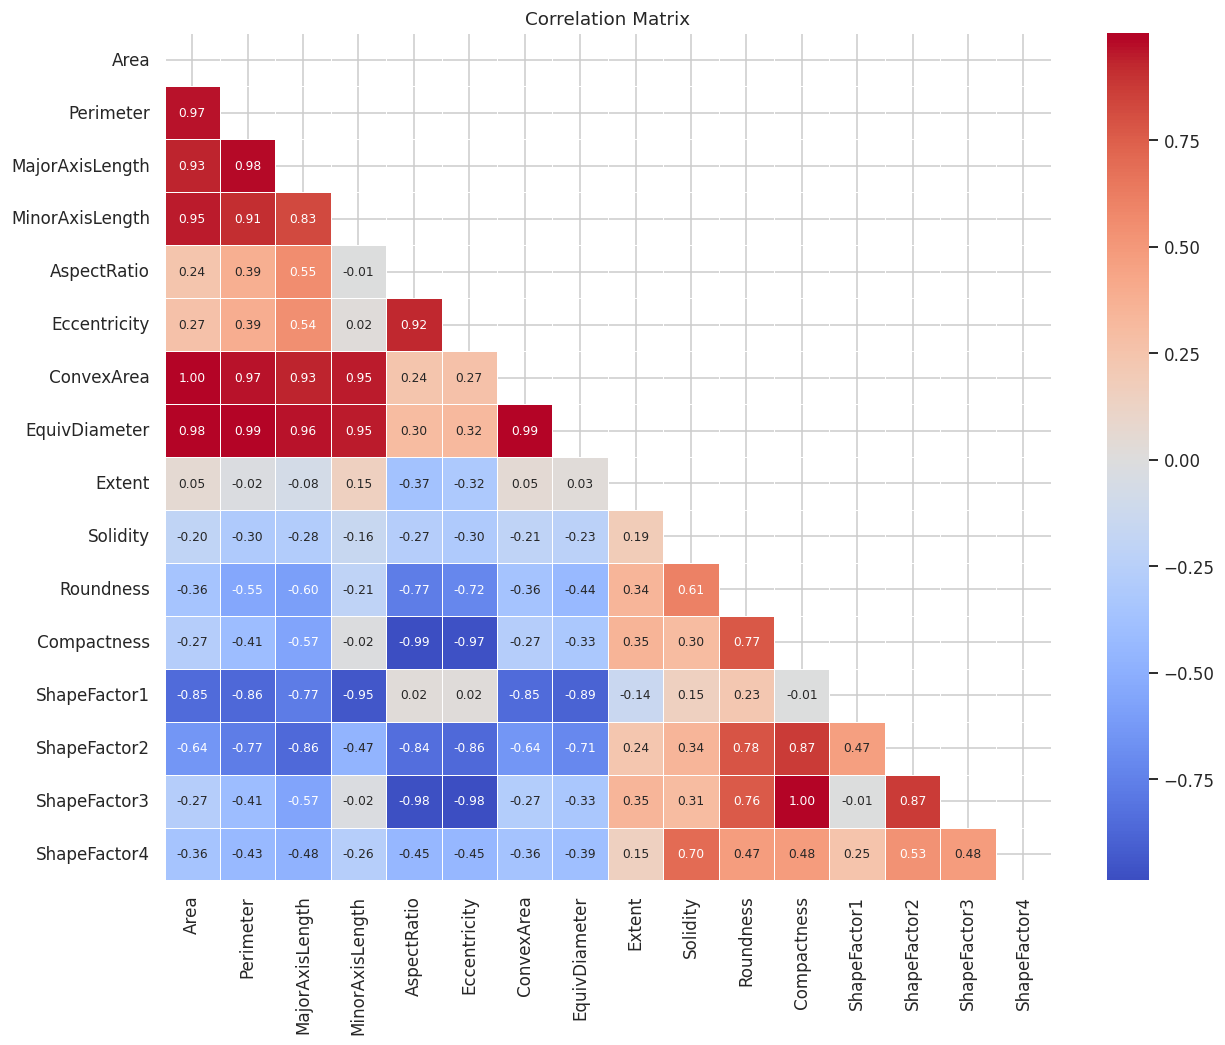

,feature_1,feature_2,corr
0,ConvexArea,Area,0.999939
1,ShapeFactor3,Compactness,0.998686
2,EquivDiameter,Perimeter,0.991380
3,Compactness,AspectRatio,-0.987687
4,EquivDiameter,ConvexArea,0.985226
5,EquivDiameter,Area,0.984968
6,ShapeFactor3,Eccentricity,-0.981058
7,ShapeFactor3,AspectRatio,-0.978592
8,MajorAxisLength,Perimeter,0.977338
9,Compactness,Eccentricity,-0.970313


In [15]:
corr = df[FEATURES].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(13, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5, annot_kws={"size": 8})
plt.title("Correlation Matrix"); plt.show()

# أعلى الأزواج ارتباطًا (|r| > 0.95) -> مؤشر على multicollinearity
pairs = corr.where(~mask).stack().reset_index()
pairs.columns = ["feature_1", "feature_2", "corr"]
pairs[pairs["corr"].abs() > 0.95].sort_values("corr", key=abs, ascending=False).reset_index(drop=True)

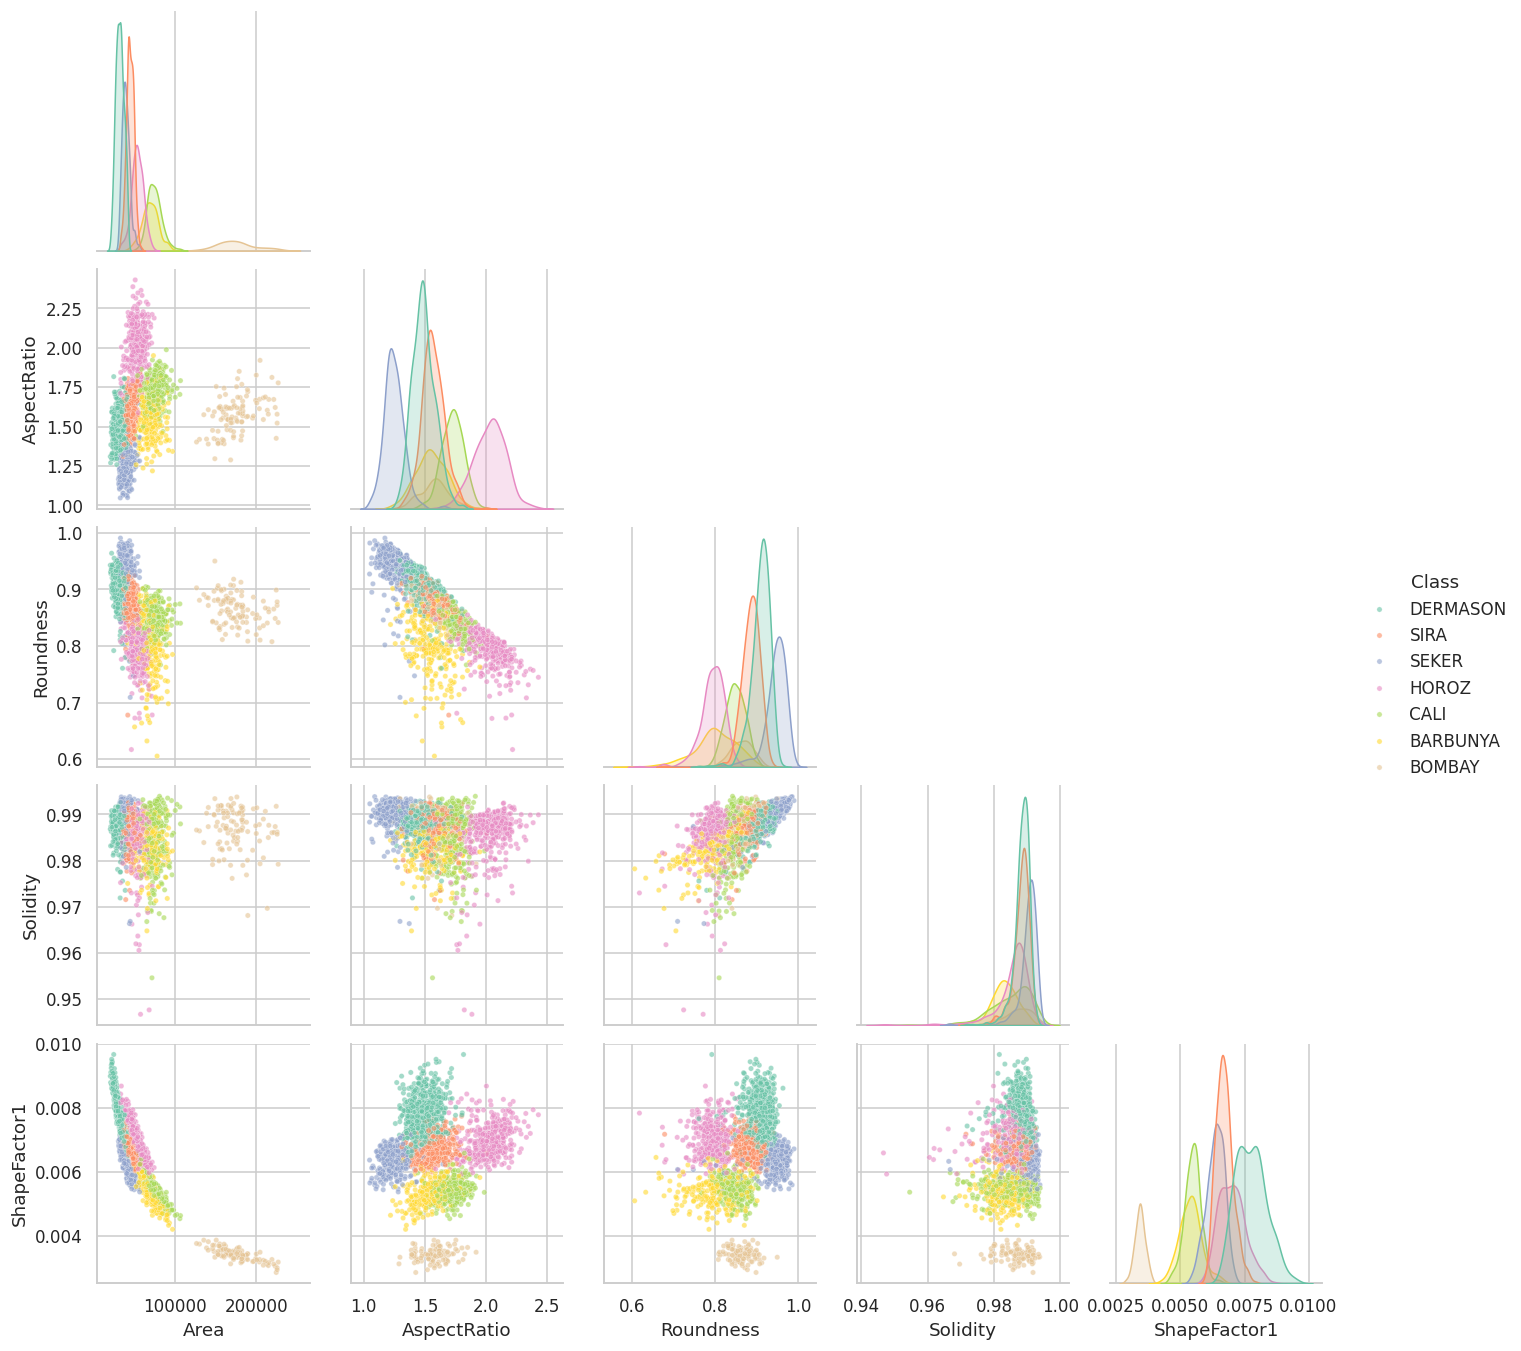

In [16]:
sample = df.sample(2500, random_state=42)
sns.pairplot(sample, vars=["Area", "AspectRatio", "Roundness", "Solidity", "ShapeFactor1"],
             hue="Class", hue_order=CLASSES, corner=True, plot_kws={"s": 12, "alpha": .6})
plt.show()

Explained variance: [0.555 0.264] | total: 0.819


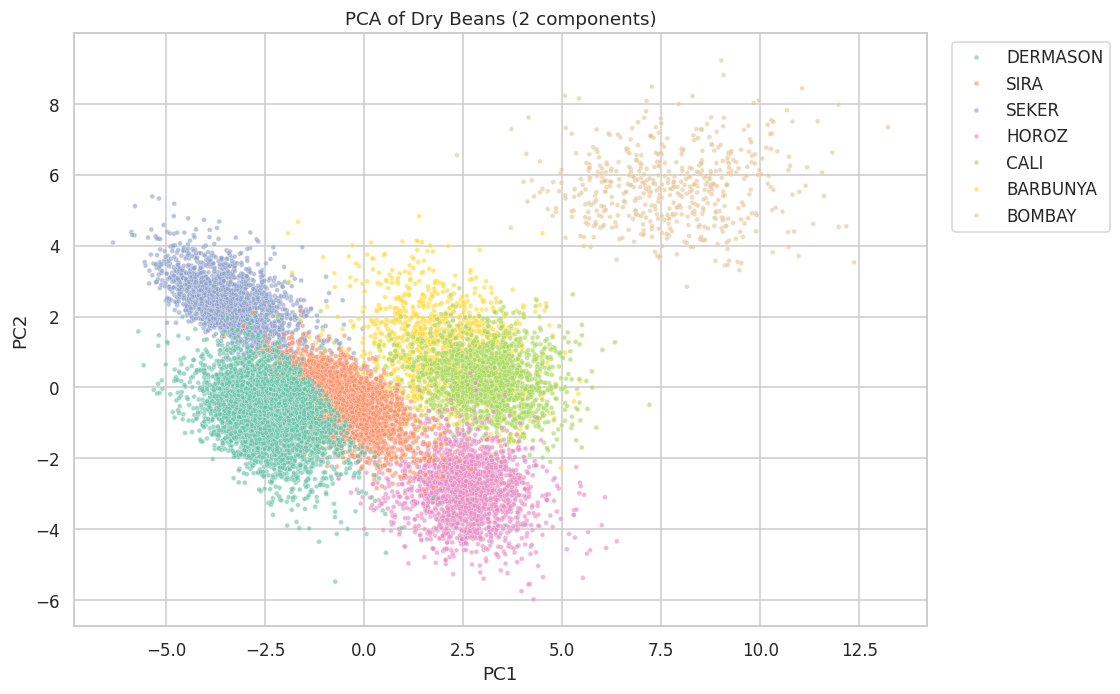

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = StandardScaler().fit_transform(df[FEATURES])
pca = PCA(n_components=2, random_state=42).fit(X)
Z = pca.transform(X)
print("Explained variance:", pca.explained_variance_ratio_.round(3), "| total:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(10, 7))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df["Class"], hue_order=CLASSES, s=10, alpha=.6)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA of Dry Beans (2 components)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.show()

In [18]:
df.groupby("Class")[["Area", "Perimeter", "MajorAxisLength", "MinorAxisLength", "AspectRatio", "Roundness"]].mean().round(2).sort_values("Area")

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Roundness
Class,,,,,,
DERMASON,32118.71,665.21,246.56,165.66,1.49,0.91
SEKER,39881.30,727.67,251.29,201.91,1.25,0.94
SIRA,44729.13,796.42,299.38,190.80,1.57,0.88
HOROZ,53648.51,919.86,372.57,184.17,2.03,0.79
BARBUNYA,69804.13,1046.11,370.04,240.31,1.54,0.80
CALI,75538.21,1057.63,409.50,236.37,1.73,0.85
BOMBAY,173485.06,1585.62,593.15,374.35,1.59,0.86


In [22]:
import pandas as pd, numpy as np, time
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
SEED = 42



In [24]:
df = pd.read_excel("/content/Dry_Bean_Dataset.xlsx", sheet_name="Dry_Beans_Dataset")
df = df.rename(columns={"AspectRation": "AspectRatio", "roundness": "Roundness"})
df = df.drop_duplicates().reset_index(drop=True)      # شيل الصفوف المكررة
print("Shape after dropping duplicates:", df.shape)

X = df.drop(columns="Class")
le = LabelEncoder()
y = le.fit_transform(df["Class"])
CLASS_NAMES = le.classes_
print("Classes:", dict(zip(range(len(CLASS_NAMES)), CLASS_NAMES)))

# Stratified split عشان نحافظ على نسب الأصناف
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Shape after dropping duplicates: (13543, 17)
Classes: {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}
Train: (10834, 16) | Test: (2709, 16)


In [25]:
models = {
    "Logistic Regression": Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=2000, random_state=SEED))]),
    "KNN":                 Pipeline([("sc", StandardScaler()), ("m", KNeighborsClassifier(n_neighbors=7))]),
    "Decision Tree":       DecisionTreeClassifier(random_state=SEED),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    "SVM (RBF)":           Pipeline([("sc", StandardScaler()), ("m", SVC(kernel="rbf", random_state=SEED))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, model in models.items():
    t0 = time.time()
    r = cross_validate(model, X_train, y_train, cv=cv,
                       scoring=["accuracy", "f1_macro"], n_jobs=-1)
    rows.append({"Model": name,
                 "CV Accuracy": r["test_accuracy"].mean(),
                 "CV Macro-F1": r["test_f1_macro"].mean(),
                 "Std": r["test_accuracy"].std(),
                 "Time (s)": round(time.time() - t0, 1)})
cv_df = pd.DataFrame(rows).sort_values("CV Accuracy", ascending=False).reset_index(drop=True)
cv_df.round(4)

,Model,CV Accuracy,CV Macro-F1,Std,Time (s)
0,SVM (RBF),0.9300,0.9416,0.0057,3.8
1,Logistic Regression,0.9243,0.9365,0.0030,3.2
2,KNN,0.9232,0.9359,0.0062,0.6
3,Random Forest,0.9231,0.9346,0.0068,41.3
4,Decision Tree,0.8952,0.9105,0.0063,1.3


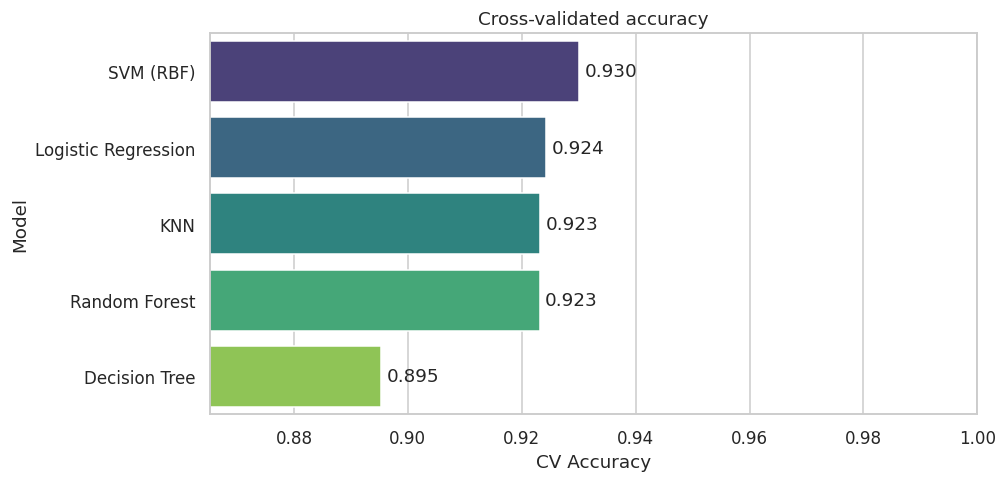

In [29]:
plt.figure(figsize=(9, 4.5))
ax = sns.barplot(data=cv_df, x="CV Accuracy", y="Model", palette="viridis")
ax.set_xlim(cv_df["CV Accuracy"].min() - 0.03, 1)
for p in ax.patches:
    ax.text(p.get_width() + 0.001, p.get_y() + p.get_height()/2, f"{p.get_width():.3f}", va="center")
plt.title("Cross-validated accuracy");
plt.show()

In [30]:
kernel_rows = []
for k in ["linear", "poly", "rbf", "sigmoid"]:
    pipe = Pipeline([("sc", StandardScaler()), ("m", SVC(kernel=k, random_state=SEED))])
    t0 = time.time()
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=-1)
    kernel_rows.append({"Kernel": k, "CV Accuracy": r["test_accuracy"].mean(),
                        "CV Macro-F1": r["test_f1_macro"].mean(), "Time (s)": round(time.time()-t0, 1)})
pd.DataFrame(kernel_rows).sort_values("CV Accuracy", ascending=False).round(4)

,Kernel,CV Accuracy,CV Macro-F1,Time (s)
2,rbf,0.9300,0.9416,5.0
0,linear,0.9274,0.9389,2.6
1,poly,0.9049,0.9206,4.4
3,sigmoid,0.7308,0.6462,5.8


In [33]:
pipe = Pipeline([("sc", StandardScaler()), ("svm", SVC(kernel="rbf", random_state=SEED))])
param_grid = {
    "svm__C":     [0.5, 1, 5, 10, 50],
    "svm__gamma": ["scale", 0.01, 0.05, 0.1],
}
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1, verbose=1)
t0 = time.time();
grid.fit(X_train, y_train)
print(f"Done in {time.time()-t0:.0f}s")
print("Best params:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Done in 113s
Best params: {'svm__C': 10, 'svm__gamma': 'scale'}
Best CV accuracy: 0.9327


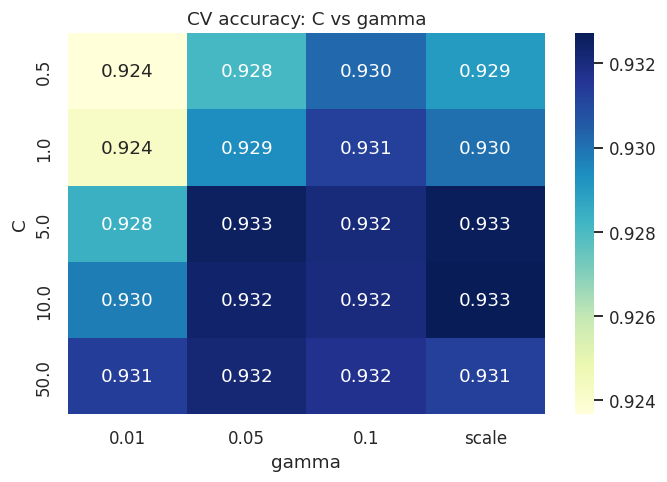

In [34]:
res = pd.DataFrame(grid.cv_results_)
heat = res.pivot_table(index="param_svm__C", columns="param_svm__gamma", values="mean_test_score", aggfunc="mean")
plt.figure(figsize=(7, 4.5))
sns.heatmap(heat.astype(float), annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("CV accuracy: C vs gamma"); plt.xlabel("gamma"); plt.ylabel("C"); plt.show()

In [35]:
best_svm = grid.best_estimator_
y_pred = best_svm.predict(X_test)

print("Test Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Test Macro-F1 :", round(f1_score(y_test, y_pred, average="macro"), 4))
print()
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

Test Accuracy : 0.9236
Test Macro-F1 : 0.9347

              precision    recall  f1-score   support

    BARBUNYA      0.924     0.913     0.918       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.924     0.939     0.932       326
    DERMASON      0.915     0.924     0.919       709
       HOROZ      0.969     0.938     0.954       372
       SEKER      0.944     0.953     0.949       406
        SIRA      0.873     0.871     0.872       527

    accuracy                          0.924      2709
   macro avg      0.936     0.934     0.935      2709
weighted avg      0.924     0.924     0.924      2709



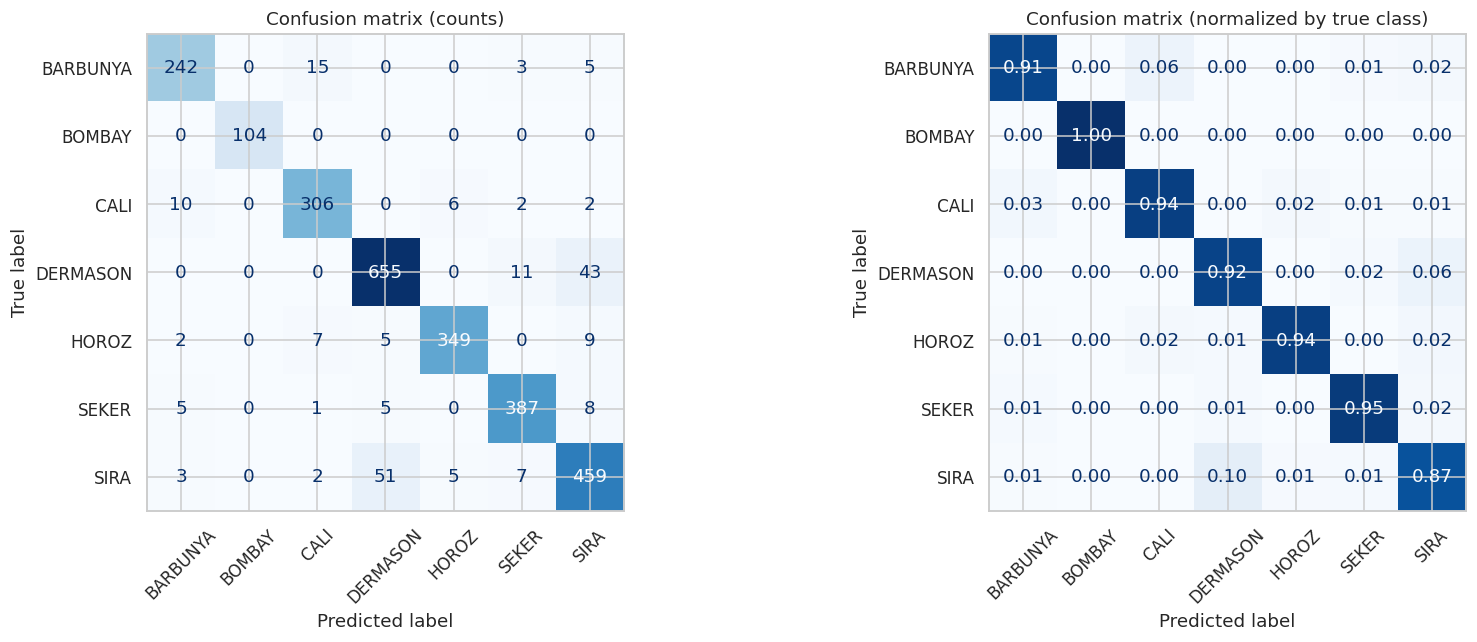

In [36]:
# Confusion matrix: أعداد + نسب
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASS_NAMES,
                                        cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASS_NAMES,
                                        normalize="true", values_format=".2f",
                                        cmap="Blues", ax=ax[1], colorbar=False)
ax[1].set_title("Confusion matrix (normalized by true class)")
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

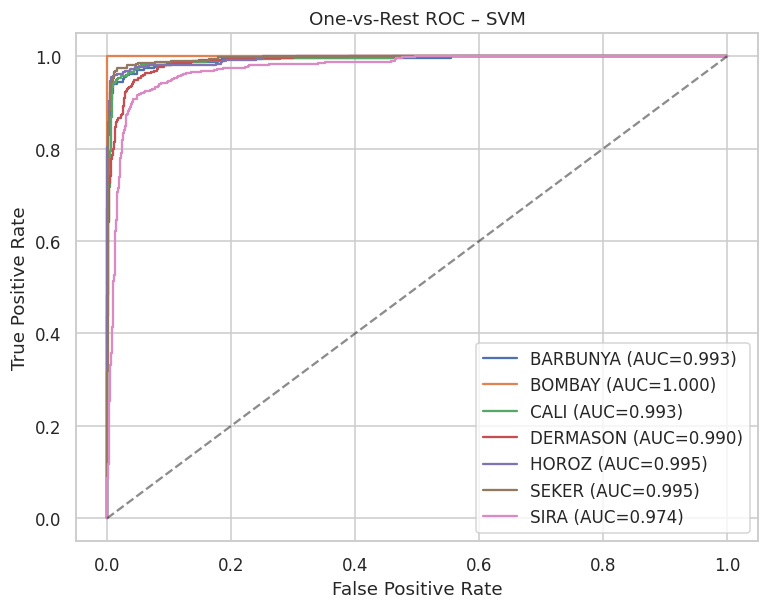

In [37]:
scores = best_svm.decision_function(X_test)           # shape (n, n_classes) – OvR shape by default
y_bin = label_binarize(y_test, classes=range(len(CLASS_NAMES)))

plt.figure(figsize=(8, 6))
for i, name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_bin[:, i], scores[:, i])
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=.5)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC – SVM"); plt.legend(loc="lower right"); plt.show()

,Model,Accuracy,Macro-F1
0,SVM (tuned),0.9236,0.9347
1,Random Forest,0.9195,0.9310
2,Logistic Regression,0.9192,0.9302
3,KNN,0.9118,0.9237
4,Decision Tree,0.8966,0.9109


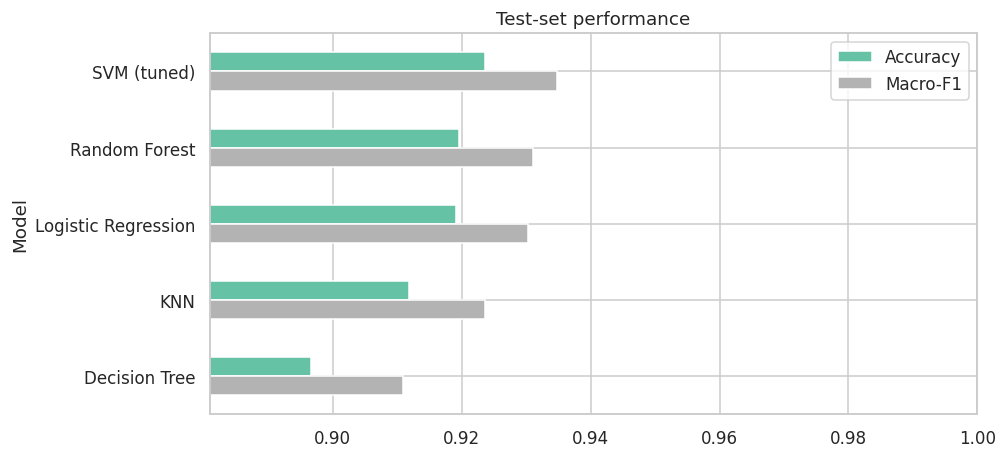

In [41]:
final = []
for name, model in models.items():
    m = best_svm if name == "SVM (RBF)" else model
    m.fit(X_train, y_train) if name != "SVM (RBF)" else None
    p = m.predict(X_test)
    final.append({"Model": "SVM (tuned)" if name == "SVM (RBF)" else name,
                  "Accuracy": accuracy_score(y_test, p),
                  "Macro-F1": f1_score(y_test, p, average="macro")})
final_df = pd.DataFrame(final).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(final_df.round(4))

final_df.set_index("Model")[["Accuracy", "Macro-F1"]].plot(kind="barh", figsize=(9, 4.5), colormap="Set2")
plt.xlim(final_df["Macro-F1"].min() - 0.03, 1); plt.title("Test-set performance"); plt.gca().invert_yaxis(); plt.show()

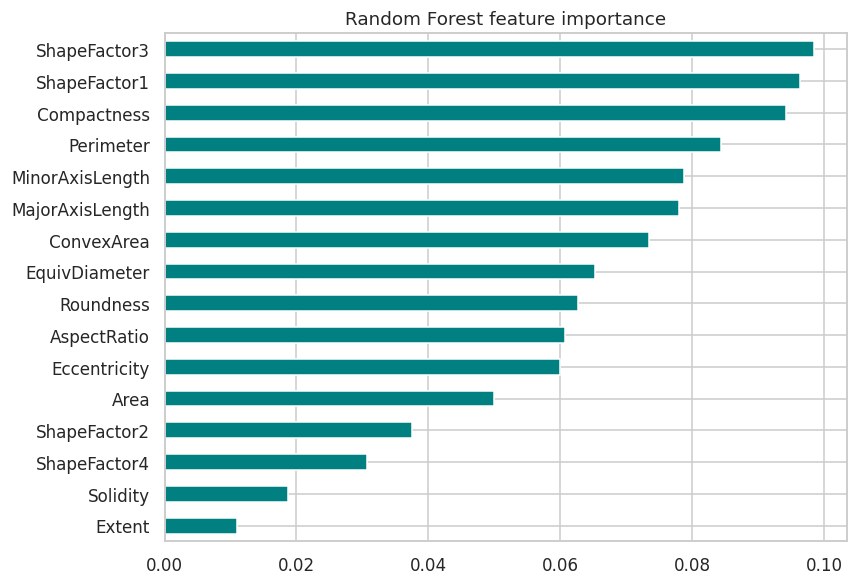

In [42]:
rf = models["Random Forest"]            # اتدرّب في الخلية السابقة
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 6), color="teal"); plt.title("Random Forest feature importance"); plt.show()

In [44]:
sample = X_test.iloc[:5]
pred = le.inverse_transform(best_svm.predict(sample))
print(pd.DataFrame({"Predicted": pred, "Actual": le.inverse_transform(y_test[:5])}))

import joblib
joblib.dump({"model": best_svm, "label_encoder": le}, "svm_dry_bean.joblib")
print("Saved: svm_dry_bean.joblib")

  Predicted    Actual
0     SEKER     SEKER
1  DERMASON  DERMASON
2  DERMASON  DERMASON
3     HOROZ     HOROZ
4     SEKER     SEKER
Saved: svm_dry_bean.joblib
